# Incidenti stradali in Italia: dove investire?

In questo progetto immagino di lavorare per una società che si occupa
di gestione del traffico e prevenzione degli incidenti.

Il mio obiettivo è individuare i comuni da approfondire per possibili
investimenti in sicurezza stradale. Considero il numero di incidenti,
il rapporto con la popolazione e la concentrazione per km².

Per il confronto comunale ho scelto il periodo 2021–2024.
Uso anche la serie storica precedente per descrivere il contesto nazionale.

In [1]:
import os
import io
import requests
import pandas as pd


os.makedirs("data", exist_ok=True)


file_istat = "data/istat_incidenti.csv"
file_situas = "data/situas_comuni.csv"
file_dataset_finale = "data/dataset_finale.csv"
file_serie_annuale = "data/serie_annuale.csv"

## Acquisizione e comprensione dei dati

Ho utilizzato l'API ISTAT per acquisire i dati sugli incidenti stradali
con lesioni a persone. Il codice scarica il file se non è già presente;
altrimenti riutilizza la copia locale.

Prima di procedere ho esaminato le colonne e i codici:
REF_AREA identifica il territorio, TIME_PERIOD l'anno e OBS_VALUE
il valore osservato. DATA_TYPE e RESULT distinguono incidenti,
feriti e morti.

Ho poi trasformato il dataset per ottenere una riga per comune e anno,
con incidenti, feriti e morti in colonne separate.

In [2]:
# Riutilizzo il CSV locale se esiste: per aggiornare i dati devo riscaricarlo.
if not os.path.exists(file_istat):
    url = "https://esploradati.istat.it/SDMXWS/rest/data/41_983"
    headers = {"Accept": "application/vnd.sdmx.data+csv;version=1.0.0"}
    risposta_http = requests.get(url, headers=headers)
    print("Stato HTTP:", risposta_http.status_code)   # 200 = tutto ok
    if risposta_http.status_code != 200:
        raise Exception("ISTAT non ha risposto correttamente: riprova tra qualche minuto")
    pd.read_csv(io.StringIO(risposta_http.text), low_memory=False).to_csv(file_istat, index=False)
    print("File scaricato")


istat_incidenti_grezzi = pd.read_csv(file_istat, low_memory=False)
print("Righe, colonne:", istat_incidenti_grezzi.shape)
print(istat_incidenti_grezzi.head())

Righe, colonne: (592635, 16)
          DATAFLOW FREQ  REF_AREA DATA_TYPE RESULT  TIME_PERIOD  OBS_VALUE  \
0  IT1:41_983(1.0)    A      1001   KILLINJ      F         2001         10   
1  IT1:41_983(1.0)    A      1001   KILLINJ      F         2002         10   
2  IT1:41_983(1.0)    A      1001   KILLINJ      F         2003          7   
3  IT1:41_983(1.0)    A      1001   KILLINJ      F         2004         13   
4  IT1:41_983(1.0)    A      1001   KILLINJ      F         2005          2   

   OBS_STATUS  NOTE_DS  NOTE_REF_AREA  NOTE_DATA_TYPE  NOTE_RESULT  \
0         NaN      NaN            NaN             NaN          NaN   
1         NaN      NaN            NaN             NaN          NaN   
2         NaN      NaN            NaN             NaN          NaN   
3         NaN      NaN            NaN             NaN          NaN   
4         NaN      NaN            NaN             NaN          NaN   

   NOTE_TIME_PERIOD  BASE_PER  UNIT_MEAS  UNIT_MULT  
0               NaN       N

In [3]:
istat_incidenti_grezzi.info()
print(istat_incidenti_grezzi[["DATA_TYPE", "RESULT"]].value_counts())
print("Anni da", istat_incidenti_grezzi["TIME_PERIOD"].min(), "a", istat_incidenti_grezzi["TIME_PERIOD"].max())
print("Aree diverse:", istat_incidenti_grezzi["REF_AREA"].nunique())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 592635 entries, 0 to 592634
Data columns (total 16 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   DATAFLOW          592635 non-null  object 
 1   FREQ              592635 non-null  object 
 2   REF_AREA          592635 non-null  int64  
 3   DATA_TYPE         592635 non-null  object 
 4   RESULT            592635 non-null  object 
 5   TIME_PERIOD       592635 non-null  int64  
 6   OBS_VALUE         592635 non-null  int64  
 7   OBS_STATUS        0 non-null       float64
 8   NOTE_DS           0 non-null       float64
 9   NOTE_REF_AREA     0 non-null       float64
 10  NOTE_DATA_TYPE    0 non-null       float64
 11  NOTE_RESULT       0 non-null       float64
 12  NOTE_TIME_PERIOD  0 non-null       float64
 13  BASE_PER          0 non-null       float64
 14  UNIT_MEAS         0 non-null       float64
 15  UNIT_MULT         0 non-null       float64
dtypes: float64(9), int64

In [4]:
incidenti_comunali_per_anno = istat_incidenti_grezzi[["REF_AREA", "TIME_PERIOD", "DATA_TYPE", "RESULT", "OBS_VALUE"]].copy()
incidenti_comunali_per_anno["codice_comune"] = incidenti_comunali_per_anno["REF_AREA"].astype(str).str.zfill(6)
incidenti_comunali_per_anno["misura"] = incidenti_comunali_per_anno["DATA_TYPE"] + "_" + incidenti_comunali_per_anno["RESULT"]
incidenti_comunali_per_anno = incidenti_comunali_per_anno.pivot(index=["codice_comune", "TIME_PERIOD"],
                  columns="misura", values="OBS_VALUE").reset_index()
incidenti_comunali_per_anno.columns.name = None
incidenti_comunali_per_anno = incidenti_comunali_per_anno.rename(columns={"TIME_PERIOD": "anno", "ROADACC_9": "incidenti",
                            "KILLINJ_F": "feriti", "KILLINJ_M": "morti"})
print(incidenti_comunali_per_anno.shape)
print(incidenti_comunali_per_anno.head())
print("Righe duplicate:", incidenti_comunali_per_anno.duplicated(["codice_comune", "anno"]).sum())
print("Valori vuoti:", incidenti_comunali_per_anno.isna().sum().sum())
print("Cifre dei codici:", incidenti_comunali_per_anno["codice_comune"].str.len().unique())

(197545, 5)
  codice_comune  anno  feriti  morti  incidenti
0        001001  2001      10      0          5
1        001001  2002      10      0          5
2        001001  2003       7      0          4
3        001001  2004      13      0          9
4        001001  2005       2      0          2
Righe duplicate: 0
Valori vuoti: 0
Cifre dei codici: [6]


## Controlli sulla qualità dei dati

Ho controllato duplicati, valori mancanti, valori estremi e copertura
degli anni. Ho verificato anche che il totale di feriti e morti
non fosse inferiore al numero di incidenti.

Non ho eliminato automaticamente i valori elevati: un comune grande
può avere molti incidenti senza che il dato sia sbagliato.

Nel 2024 ho osservato meno comuni presenti e nessuna riga con zero
incidenti. Non avendo una conferma del motivo, non ho interpretato
le righe assenti come zeri.

In [5]:
print(incidenti_comunali_per_anno.nlargest(10, "incidenti"))
print(incidenti_comunali_per_anno[["incidenti", "feriti", "morti"]].describe())
righe_incoerenti = incidenti_comunali_per_anno[(incidenti_comunali_per_anno["feriti"] + incidenti_comunali_per_anno["morti"]) < incidenti_comunali_per_anno["incidenti"]]
print("\nRighe incoerenti:", len(righe_incoerenti))
totali_nazionali_per_anno = incidenti_comunali_per_anno.groupby("anno").agg(comuni=("codice_comune", "nunique"),
                                    incidenti=("incidenti", "sum"))
print("\n", totali_nazionali_per_anno)

anni_disponibili_per_comune = incidenti_comunali_per_anno.groupby("codice_comune")["anno"].count()
print("\nComuni per numero di anni disponibili:")
print(anni_disponibili_per_comune.value_counts().sort_index())

       codice_comune  anno  feriti  morti  incidenti
120088        058091  2004   30254    260      23135
120085        058091  2001   27865    305      22220
120089        058091  2005   28653    237      21902
120090        058091  2006   28209    231      21452
120086        058091  2002   26696    363      21330
120087        058091  2003   26638    165      20426
120091        058091  2007   26299    201      19960
120093        058091  2009   24638    198      18561
120094        058091  2010   24467    182      18496
120095        058091  2011   24164    186      18235
           incidenti         feriti          morti
count  197545.000000  197545.000000  197545.000000
mean       25.089716      35.165901       0.530573
std       256.783174     336.717433       2.765023
min         0.000000       0.000000       0.000000
25%         1.000000       1.000000       0.000000
50%         4.000000       5.000000       0.000000
75%        12.000000      18.000000       0.000000
max     2

In [6]:
comuni_con_zero_incidenti = incidenti_comunali_per_anno.assign(zero=incidenti_comunali_per_anno["incidenti"] == 0).groupby("anno")["zero"].sum()
print(comuni_con_zero_incidenti.tail(6))

comuni_presenti_2023 = set(incidenti_comunali_per_anno.loc[incidenti_comunali_per_anno["anno"] == 2023, "codice_comune"])
comuni_presenti_2024 = set(incidenti_comunali_per_anno.loc[incidenti_comunali_per_anno["anno"] == 2024, "codice_comune"])
comuni_assenti_nel_2024 = comuni_presenti_2023 - comuni_presenti_2024
print("\nComuni presenti nel 2023 e assenti nel 2024:", len(comuni_assenti_nel_2024))

incidenti_2023_comuni_assenti = incidenti_comunali_per_anno[(incidenti_comunali_per_anno["anno"] == 2023) & (incidenti_comunali_per_anno["codice_comune"].isin(comuni_assenti_nel_2024))]
print(incidenti_2023_comuni_assenti["incidenti"].describe())

anno
2020    1965
2021    1695
2022    1662
2023    1643
2024       0
2025       0
Name: zero, dtype: int64

Comuni presenti nel 2023 e assenti nel 2024: 1566
count    1566.000000
mean        0.636654
std         1.142906
min         0.000000
25%         0.000000
50%         0.000000
75%         1.000000
max        15.000000
Name: incidenti, dtype: float64


## Integrazione con SITUAS

I dati sugli incidenti non contengono tutte le informazioni necessarie
per confrontare i comuni. Ho quindi aggiunto da SITUAS nome,
popolazione residente e superficie.

Ho uniformato i codici comunali a sei cifre e convertito i valori
numerici nel formato corretto.

Alcuni codici non trovano corrispondenza nell'anagrafica utilizzata.
Ho controllato quante righe e quanti incidenti riguardano queste
mancate corrispondenze, senza attribuirle tutte a una causa certa.

Popolazione e superficie si riferiscono al 2020:
questo è un limite dei confronti con gli incidenti del 2021–2024.

In [7]:
situas_grezzo = pd.read_csv(file_situas,
                     sep=None, engine="python", dtype=str, encoding="utf-8-sig")

print(situas_grezzo.shape)
print(situas_grezzo.head())

(7903, 17)
  Codice Ripartizione geografica Codice Regione Codice Provincia (Storico)  \
0                              1             01                        001   
1                              1             01                        001   
2                              1             01                        001   
3                              1             01                        001   
4                              1             01                        001   

  Codice Provincia/Uts Codice Comune (alfanumerico) Codice Comune (numerico)  \
0                  201                       001001                     1001   
1                  201                       001002                     1002   
2                  201                       001003                     1003   
3                  201                       001004                     1004   
4                  201                       001006                     1006   

            Comune Comune (dizione stra

In [8]:
anagrafica_comuni = situas_grezzo[["Codice Comune (alfanumerico)", "Comune", "Popolazione residente", "Superficie (Kmq)"]].copy()
anagrafica_comuni.columns = ["codice_comune", "comune", "popolazione", "superficie_kmq"]

anagrafica_comuni["popolazione"] = anagrafica_comuni["popolazione"].astype(int)
anagrafica_comuni["superficie_kmq"] = (anagrafica_comuni["superficie_kmq"]
                         .str.replace(".", "", regex=False)
                         .str.replace(",", ".", regex=False)
                         .astype(float))

print(anagrafica_comuni.head())
print(anagrafica_comuni.dtypes)
print("Superficie massima:", anagrafica_comuni["superficie_kmq"].max())

  codice_comune           comune  popolazione  superficie_kmq
0        001001            Agliè         2545         13.1462
1        001002          Airasca         3633         15.7393
2        001003     Ala di Stura          459         46.3315
3        001004  Albiano d'Ivrea         1638         11.7314
4        001006           Almese         6355         17.8756
codice_comune      object
comune             object
popolazione         int64
superficie_kmq    float64
dtype: object
Superficie massima: 1287.3716


In [9]:
incidenti_con_anagrafica = incidenti_comunali_per_anno.merge(anagrafica_comuni, on="codice_comune", how="left")

print("Righe:", len(incidenti_con_anagrafica))
print("Righe senza corrispondenza in SITUAS:", incidenti_con_anagrafica["comune"].isna().sum())
print(incidenti_con_anagrafica[incidenti_con_anagrafica["codice_comune"] == "058091"].head(2))

Righe: 197545
Righe senza corrispondenza in SITUAS: 8320
       codice_comune  anno  feriti  morti  incidenti comune  popolazione  \
120085        058091  2001   27865    305      22220   Roma    2770226.0   
120086        058091  2002   26696    363      21330   Roma    2770226.0   

        superficie_kmq  
120085       1287.3716  
120086       1287.3716  


In [10]:
codici_senza_corrispondenza = incidenti_con_anagrafica[incidenti_con_anagrafica["comune"].isna()]

print("Codici senza corrispondenza:", codici_senza_corrispondenza["codice_comune"].nunique())
print("Incidenti in quelle righe:", codici_senza_corrispondenza["incidenti"].sum(), "su", incidenti_con_anagrafica["incidenti"].sum())
print("Percentuale:", round(codici_senza_corrispondenza["incidenti"].sum() / incidenti_con_anagrafica["incidenti"].sum() * 100, 2), "%")
print(codici_senza_corrispondenza["anno"].value_counts().sort_index())

Codici senza corrispondenza: 676
Incidenti in quelle righe: 87590 su 4956348
Percentuale: 1.77 %
anno
2001    553
2002    553
2003    553
2004    551
2005    551
2006    588
2007    588
2008    588
2009    586
2010    466
2011    463
2012    463
2013    463
2014    405
2015    386
2016    312
2017    123
2018     80
2019     17
2020      2
2021      4
2022      4
2023      6
2024      8
2025      7
Name: count, dtype: int64


In [11]:
# Manteniamo solo le righe osservate con anagrafica disponibile.
# Non aggiungiamo zeri ai comuni assenti nel 2024.

incidenti_comuni_validi = incidenti_con_anagrafica[
    incidenti_con_anagrafica["comune"].notna()
].copy()


periodo = incidenti_comuni_validi[
    incidenti_comuni_validi["anno"].between(2021, 2024)
]

anni_per_comune = periodo.groupby("codice_comune")["anno"].nunique()

print("Numero di comuni per anni disponibili:")
display(
    anni_per_comune.value_counts()
    .sort_index()
    .rename_axis("anni_disponibili")
    .to_frame("numero_comuni")
)

codici_10mila = anagrafica_comuni.loc[
    anagrafica_comuni["popolazione"] >= 10000,
    "codice_comune"
]

comuni_10mila_incompleti = anagrafica_comuni[
    anagrafica_comuni["codice_comune"].isin(codici_10mila)
].copy()

comuni_10mila_incompleti["anni_disponibili"] = (
    comuni_10mila_incompleti["codice_comune"]
    .map(anni_per_comune)
    .fillna(0)
    .astype(int)
)

comuni_10mila_incompleti = comuni_10mila_incompleti[
    comuni_10mila_incompleti["anni_disponibili"] < 4
]

print("Comuni con almeno 10.000 abitanti e dati incompleti:")
display(
    comuni_10mila_incompleti[
        ["codice_comune", "comune", "popolazione", "anni_disponibili"]
    ]
)

Numero di comuni per anni disponibili:


,numero_comuni
anni_disponibili,
2,5
3,1564
4,6331


Comuni con almeno 10.000 abitanti e dati incompleti:


,codice_comune,comune,popolazione,anni_disponibili


In [12]:
# Confronto solo comuni con quattro anni disponibili, senza aggiungere zeri.
periodo = incidenti_comuni_validi[
    incidenti_comuni_validi["anno"].between(2021, 2024)
]

copertura_anni = periodo.groupby("codice_comune")["anno"].nunique()

codici_completi = copertura_anni[
    copertura_anni == 4
].index

print("Comuni con quattro anni disponibili:", len(codici_completi))

Comuni con quattro anni disponibili: 6331


In [13]:
incidenti_comuni_validi = incidenti_con_anagrafica[
    incidenti_con_anagrafica["comune"].notna()
].copy()

print("Righe dopo l'esclusione:", len(incidenti_comuni_validi))

Righe dopo l'esclusione: 189225


## Periodo di confronto e indicatori

Ho mantenuto nella sintesi solo i comuni con osservazioni disponibili
in tutti e quattro gli anni 2021–2024: sono 6.331.

Per ciascuno ho calcolato incidenti, feriti e morti medi annui,
oltre agli incidenti per 1.000 abitanti e per km².

Per le graduatorie ho scelto i comuni con almeno 10.000 abitanti:
sono 1.206 e hanno tutti quattro anni disponibili.
Questa soglia riduce l'instabilità dei tassi nei comuni molto piccoli,
ma non la elimina completamente.

Ho aggiunto anche i morti per 100.000 abitanti e per 100 incidenti.
Quest'ultimo indicatore non è la percentuale di incidenti mortali,
ma il rapporto tra decessi e incidenti.

In [14]:
# Seleziono gli anni 2021-2024.
periodo = incidenti_comuni_validi[
    incidenti_comuni_validi["anno"].between(2021, 2024)
].copy()

# Mantengo i comuni con tutti e quattro gli anni disponibili.
copertura_anni = periodo.groupby("codice_comune")["anno"].nunique()
codici_completi = copertura_anni[copertura_anni == 4].index

periodo_2021_2024 = periodo[
    periodo["codice_comune"].isin(codici_completi)
].copy()

comuni_sintesi = (
    periodo_2021_2024
    .groupby(
        ["codice_comune", "comune", "popolazione", "superficie_kmq"],
        as_index=False
    )[["incidenti", "feriti", "morti"]]
    .mean()
    .rename(columns={
        "incidenti": "incidenti_medi",
        "feriti": "feriti_medi",
        "morti": "morti_medi"
    })
)

# Uso la popolazione del 2020 come riferimento per tutto il periodo.
comuni_sintesi["incidenti_x_1000ab"] = (
    comuni_sintesi["incidenti_medi"]
    / comuni_sintesi["popolazione"] * 1000
)

comuni_sintesi["incidenti_x_kmq"] = (
    comuni_sintesi["incidenti_medi"]
    / comuni_sintesi["superficie_kmq"]
)

print("Dimensioni della sintesi:", comuni_sintesi.shape)

display(
    comuni_sintesi.nlargest(5, "incidenti_x_1000ab")[
        ["comune", "popolazione", "incidenti_medi", "incidenti_x_1000ab"]
    ]
)

Dimensioni della sintesi: (6331, 9)


,comune,popolazione,incidenti_medi,incidenti_x_1000ab
2071,Ponte Gardena/Waidbruck,201.0,3.50,17.412935
1040,Brienno,335.0,5.75,17.164179
361,Argentera,78.0,1.25,16.025641
4522,Rocca Pia,181.0,2.75,15.193370
886,Carrodano,476.0,7.00,14.705882


In [15]:
# Mortalità rispetto alla popolazione residente del 2020.
comuni_sintesi["morti_x_100000ab"] = (
    comuni_sintesi["morti_medi"]
    / comuni_sintesi["popolazione"] * 100000
)

# Decessi ogni 100 incidenti: rapporto fra persone ed eventi,
# non percentuale di incidenti mortali.
comuni_sintesi["morti_x_100incidenti"] = (
    comuni_sintesi["morti_medi"]
    / comuni_sintesi["incidenti_medi"].replace(0, float("nan"))
    * 100
)

comuni_sintesi["pop_ge_10000"] = (
    comuni_sintesi["popolazione"] >= 10000
)

display(
    comuni_sintesi[
        comuni_sintesi["pop_ge_10000"]
    ].nlargest(10, "morti_medi")[
        [
            "comune",
            "incidenti_medi",
            "morti_medi",
            "morti_x_100000ab",
            "morti_x_100incidenti"
        ]
    ].round(2)
)

,comune,incidenti_medi,morti_medi,morti_x_100000ab,morti_x_100incidenti
3890,Roma,12762.75,139.75,5.04,1.09
1271,Milano,7700.75,40.75,2.96,0.53
4204,Napoli,2355.75,31.75,3.44,1.35
5323,Palermo,1818.75,21.75,3.41,1.20
199,Torino,2903.50,21.25,2.48,0.73
3101,Bologna,2035.75,16.75,4.28,0.82
5502,Catania,1341.50,15.50,5.16,1.16
3185,Ravenna,758.75,14.25,9.11,1.88
844,Genova,3758.75,14.00,2.47,0.37
2345,Verona,1195.25,13.50,5.23,1.13


In [16]:
print(comuni_sintesi["popolazione"].describe())
print("Comuni sotto 1.000 ab.:", (comuni_sintesi["popolazione"] < 1000).sum())
print("Comuni sotto 5.000 ab.:", (comuni_sintesi["popolazione"] < 5000).sum())

comuni_oltre_10mila = comuni_sintesi[comuni_sintesi["popolazione"] >= 10000]
print("\nComuni con almeno 10.000 ab.:", len(comuni_oltre_10mila))

print("\nTop 10 per 1.000 abitanti:")
print(comuni_oltre_10mila.nlargest(10, "incidenti_x_1000ab")[["comune", "popolazione", "incidenti_medi", "incidenti_x_1000ab"]])

print("\nTop 10 per km²:")
print(comuni_oltre_10mila.nlargest(10, "incidenti_x_kmq")[["comune", "popolazione", "incidenti_medi", "incidenti_x_kmq"]])


count    6.331000e+03
mean     9.141388e+03
std      4.663021e+04
min      5.200000e+01
25%      1.548000e+03
50%      3.367000e+03
75%      7.753000e+03
max      2.770226e+06
Name: popolazione, dtype: float64
Comuni sotto 1.000 ab.: 897
Comuni sotto 5.000 ab.: 3966

Comuni con almeno 10.000 ab.: 1206

Top 10 per 1.000 abitanti:
                    comune  popolazione  incidenti_medi  incidenti_x_1000ab
1349               Bergamo     119993.0          890.50            7.421266
846                Lavagna      12352.0           89.75            7.266030
3449             Calenzano      18420.0          125.75            6.826819
844                 Genova     566410.0         3758.75            6.636094
6018              Riccione      34942.0          229.50            6.568027
3447  Barberino di Mugello      10870.0           71.00            6.531739
3458               Firenze     368419.0         2381.50            6.464107
789          Finale Ligure      11304.0           72.50      

In [17]:
comuni_sintesi["pop_ge_10000"] = comuni_sintesi["popolazione"] >= 10000

comuni_sopra_soglia = comuni_sintesi[comuni_sintesi["pop_ge_10000"]]
print("Comuni con almeno 10.000 ab.:", len(comuni_sopra_soglia), "su", len(comuni_sintesi))
print("Quota di popolazione:", round(comuni_sopra_soglia["popolazione"].sum() / comuni_sintesi["popolazione"].sum() * 100, 1), "%")
print("Quota di incidenti:  ", round(comuni_sopra_soglia["incidenti_medi"].sum() / comuni_sintesi["incidenti_medi"].sum() * 100, 1), "%")

comuni_sintesi.to_csv(file_dataset_finale, index=False)
print("Salvato:", comuni_sintesi.shape)

Comuni con almeno 10.000 ab.: 1206 su 6331
Quota di popolazione: 71.2 %
Quota di incidenti:   81.5 %
Salvato: (6331, 12)


## Analisi esplorativa

Ho utilizzato i grafici per osservare l'andamento storico,
la distribuzione dei tassi e il rapporto fra popolazione e incidenti.

Nel 2020 emerge una forte diminuzione, coerente con le limitazioni
alla mobilità durante la pandemia. Nel 2024 il numero nazionale
di incidenti torna vicino al livello del 2019.

I grafici comunali mostrano perché il solo numero assoluto non basta:
volume, tasso per abitante e densità territoriale descrivono
aspetti diversi del problema.

I riferimenti calcolati sulla sintesi dei 6.331 comuni descrivono
il campione analizzato, non l'intero territorio nazionale.

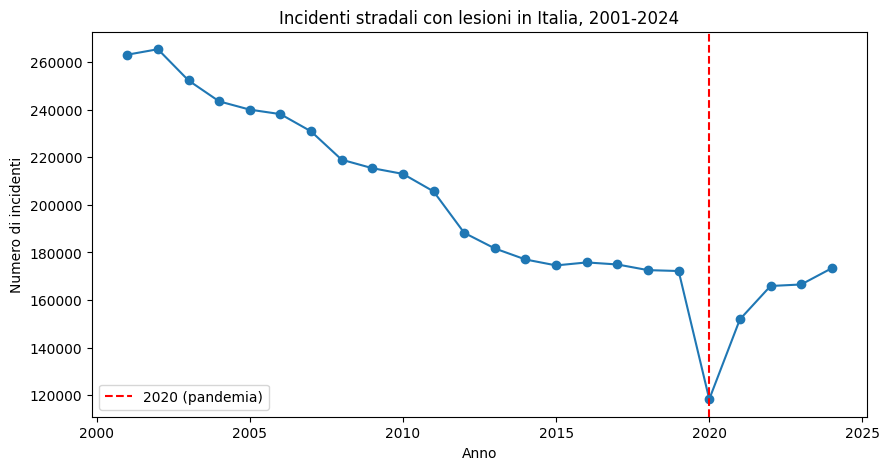

      incidenti  feriti  morti
anno                          
2001     263100  373286   7096
2019     172183  241384   3173
2020     118298  159248   2395
2024     173364  233853   3030


In [18]:
import matplotlib.pyplot as plt

totali_nazionali_per_anno = (
    incidenti_comunali_per_anno[
        incidenti_comunali_per_anno["anno"].between(2001, 2024)
    ]
    .groupby("anno")[["incidenti", "feriti", "morti"]]
    .sum()
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(totali_nazionali_per_anno.index, totali_nazionali_per_anno["incidenti"], marker="o")
ax.axvline(2020, color="red", linestyle="--", label="2020 (pandemia)")
ax.set_title("Incidenti stradali con lesioni in Italia, 2001-2024")
ax.set_xlabel("Anno")
ax.set_ylabel("Numero di incidenti")
ax.legend()
plt.show()

print(totali_nazionali_per_anno.loc[[2001, 2019, 2020, 2024]])

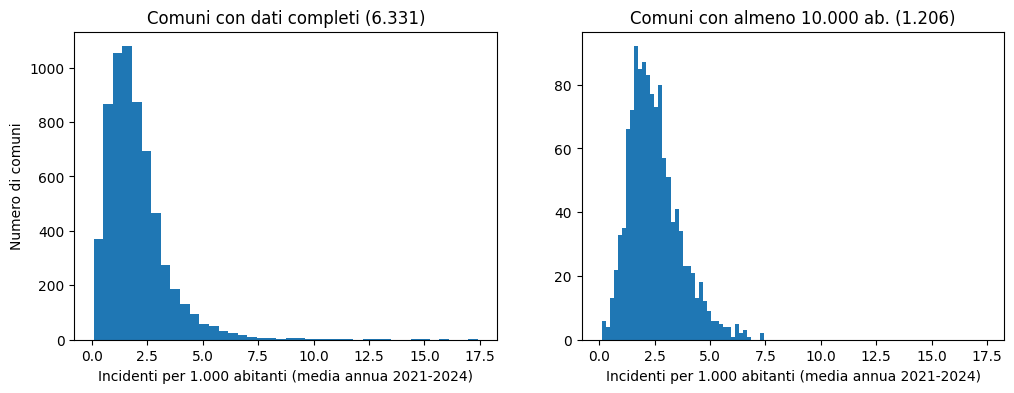

               count  mean   std   min   25%   50%   75%    max
pop_ge_10000                                                   
False         5125.0   1.9  1.46  0.08  0.99  1.59  2.37  17.41
True          1206.0   2.5  1.16  0.12  1.68  2.32  3.13   7.42


In [19]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharex=True)

ax1.hist(comuni_sintesi["incidenti_x_1000ab"], bins=40)
ax1.set_title("Comuni con dati completi (6.331)")

ax2.hist(comuni_sintesi[comuni_sintesi["pop_ge_10000"]]["incidenti_x_1000ab"], bins=40)
ax2.set_title("Comuni con almeno 10.000 ab. (1.206)")

for ax in (ax1, ax2):
    ax.set_xlabel("Incidenti per 1.000 abitanti (media annua 2021-2024)")
ax1.set_ylabel("Numero di comuni")
plt.show()

print(comuni_sintesi.groupby("pop_ge_10000")["incidenti_x_1000ab"].describe().round(2))

Comuni con zero incidenti (non mostrati): 0


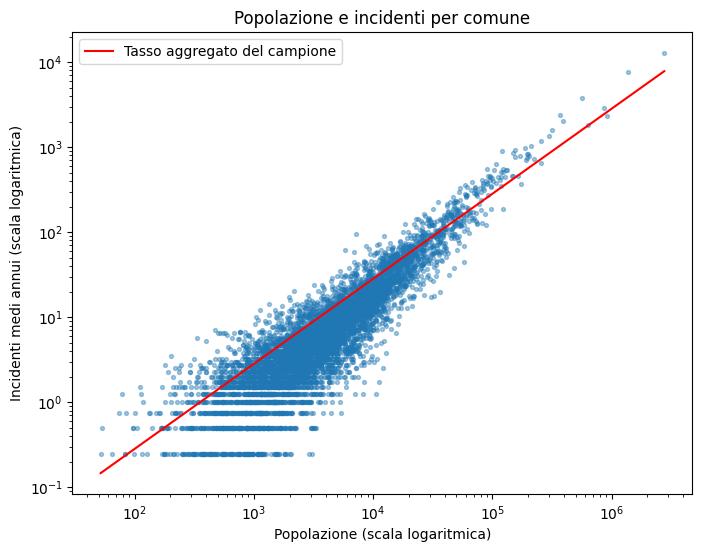

In [20]:
import numpy as np

comuni_con_incidenti = comuni_sintesi[comuni_sintesi["incidenti_medi"] > 0]
print("Comuni con zero incidenti (non mostrati):", len(comuni_sintesi) - len(comuni_con_incidenti))

tasso_medio_nazionale = comuni_sintesi["incidenti_medi"].sum() / comuni_sintesi["popolazione"].sum()
intervallo_popolazione = np.array([comuni_sintesi["popolazione"].min(), comuni_sintesi["popolazione"].max()])

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(comuni_con_incidenti["popolazione"], comuni_con_incidenti["incidenti_medi"], s=8, alpha=0.4)
ax.plot(intervallo_popolazione, intervallo_popolazione * tasso_medio_nazionale, color="red", label="Tasso aggregato del campione")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Popolazione (scala logaritmica)")
ax.set_ylabel("Incidenti medi annui (scala logaritmica)")
ax.set_title("Popolazione e incidenti per comune")
ax.legend()
plt.show()

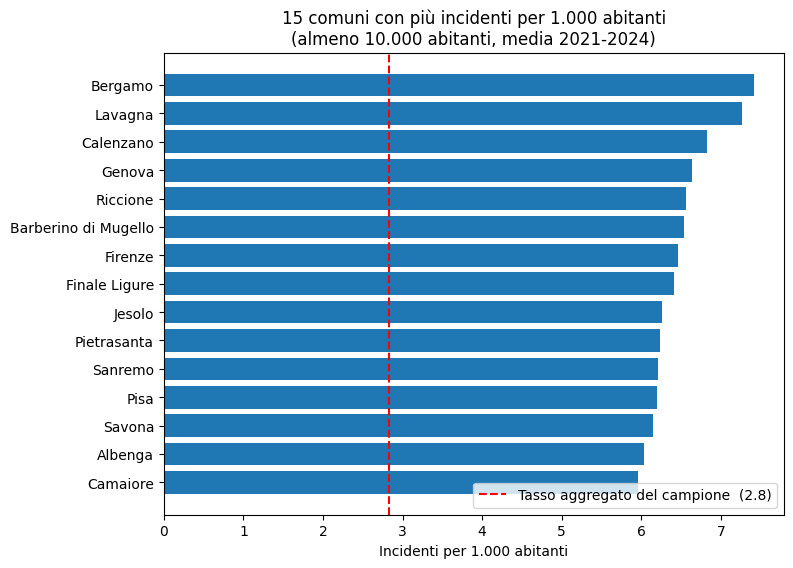

In [21]:
top_15_per_mille = (comuni_sintesi[comuni_sintesi["pop_ge_10000"]]
       .nlargest(15, "incidenti_x_1000ab")
       .sort_values("incidenti_x_1000ab"))

media_nazionale_per_1000ab = comuni_sintesi["incidenti_medi"].sum() / comuni_sintesi["popolazione"].sum() * 1000

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top_15_per_mille["comune"], top_15_per_mille["incidenti_x_1000ab"])
ax.axvline(media_nazionale_per_1000ab, color="red", linestyle="--", label=f"Tasso aggregato del campione  ({media_nazionale_per_1000ab:.1f})")
ax.set_title("15 comuni con più incidenti per 1.000 abitanti\n(almeno 10.000 abitanti, media 2021-2024)")
ax.set_xlabel("Incidenti per 1.000 abitanti")
ax.legend(loc="lower right")
plt.show()

## Raggruppamento dei comuni

Ho utilizzato K-means per cercare comuni con caratteristiche simili,
considerando tasso di incidenti, densità degli incidenti e popolazione.

Ho applicato il logaritmo a densità e popolazione e standardizzato
le tre variabili, per evitare che scale diverse dominassero il risultato.

Ho confrontato da due a sei cluster. La soluzione con due gruppi
ha la silhouette più alta fra quelle provate: 0,365.

Ho ottenuto un gruppo di 398 comuni con tasso e concentrazione maggiori
e uno di 808 con valori minori. Sono profili relativi al campione:
non indicano comuni sicuri o pericolosi in senso assoluto.

In [22]:
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

comuni_oltre_10mila = comuni_sintesi[comuni_sintesi["pop_ge_10000"]].copy()

comuni_oltre_10mila["log_densita"] = np.log10(comuni_oltre_10mila["incidenti_x_kmq"])
comuni_oltre_10mila["log_popolazione"] = np.log10(comuni_oltre_10mila["popolazione"])

colonne = ["incidenti_x_1000ab", "log_densita", "log_popolazione"]
X = StandardScaler().fit_transform(comuni_oltre_10mila[colonne])

comuni_oltre_10mila["gruppo"] = KMeans(
    n_clusters=2,
    n_init=10,
    random_state=42
).fit_predict(X)


In [23]:
from sklearn.metrics import silhouette_score

risultati_cluster = []

# X contiene gli indicatori già trasformati e standardizzati.
for k in range(2, 7):
    modello_k = KMeans(
        n_clusters=k,
        n_init=10,
        random_state=42
    )

    etichette = modello_k.fit_predict(X)

    risultati_cluster.append({
        "numero_cluster": k,
        "silhouette": silhouette_score(X, etichette),
        "cluster_piu_piccolo": pd.Series(etichette).value_counts().min()
    })

display(pd.DataFrame(risultati_cluster).round(3))

,numero_cluster,silhouette,cluster_piu_piccolo
0,2,0.365,398
1,3,0.280,152
2,4,0.276,110
3,5,0.258,96
4,6,0.265,88


In [24]:
# Identifico il profilo dai valori: i numeri dei cluster sono solo etichette.
tassi_cluster = comuni_oltre_10mila.groupby(
    "gruppo"
)["incidenti_x_1000ab"].median()

gruppo_alto = tassi_cluster.idxmax()

nomi = {
    gruppo: (
        "Incidentalità e concentrazione maggiori"
        if gruppo == gruppo_alto
        else "Incidentalità e concentrazione minori"
    )
    for gruppo in tassi_cluster.index
}

comuni_sintesi = comuni_sintesi.drop(
    columns=["gruppo", "profilo"],
    errors="ignore"
)

comuni_sintesi = comuni_sintesi.merge(
    comuni_oltre_10mila[["codice_comune", "gruppo"]],
    on="codice_comune",
    how="left",
    validate="one_to_one"
)

comuni_sintesi["profilo"] = (
    comuni_sintesi["gruppo"]
    .map(nomi)
    .fillna("Sotto 10.000 ab. — non classificato")
)

display(comuni_sintesi["profilo"].value_counts())

,count
profilo,
Sotto 10.000 ab. — non classificato,5125
Incidentalità e concentrazione minori,808
Incidentalità e concentrazione maggiori,398


In [25]:
situas_grezzo.columns = situas_grezzo.columns.str.replace("\ufeff", "", regex=False)
print(list(situas_grezzo.columns)[:3])

['Codice Ripartizione geografica', 'Codice Regione', 'Codice Provincia (Storico)']


ripartizione
Nord-Ovest    2277
Sud           1337
Nord-Est      1271
Centro         846
Isole          600
Name: count, dtype: int64
       comune ripartizione
199    Torino   Nord-Ovest
3890     Roma       Centro
4204   Napoli          Sud
5323  Palermo        Isole
ripartizione
Nord-Ovest    2.39
Nord-Est      2.63
Centro        2.94
Sud           1.79
Isole         1.81
Name: incidenti_x_1000ab, dtype: float64


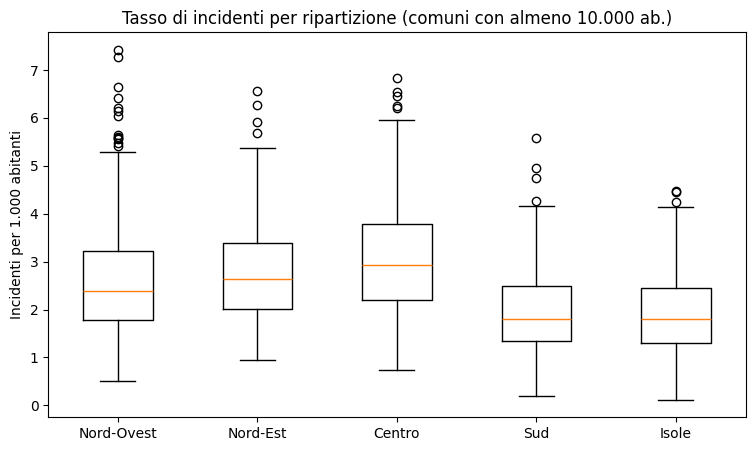

In [26]:
mappa_ripartizioni = situas_grezzo[["Codice Comune (alfanumerico)", "Codice Ripartizione geografica"]].copy()
mappa_ripartizioni.columns = ["codice_comune", "cod_rip"]
mappa_ripartizioni["ripartizione"] = mappa_ripartizioni["cod_rip"].map({"1": "Nord-Ovest", "2": "Nord-Est",
                                          "3": "Centro", "4": "Sud", "5": "Isole"})

comuni_sintesi = comuni_sintesi.drop(columns=["ripartizione"], errors="ignore")
comuni_sintesi = comuni_sintesi.merge(mappa_ripartizioni[["codice_comune", "ripartizione"]], on="codice_comune", how="left")

print(comuni_sintesi["ripartizione"].value_counts(dropna=False))
print(comuni_sintesi[comuni_sintesi["comune"].isin(["Torino", "Roma", "Napoli", "Palermo"])][["comune", "ripartizione"]])

ordine = ["Nord-Ovest", "Nord-Est", "Centro", "Sud", "Isole"]
comuni_10mila_plus = comuni_sintesi[comuni_sintesi["pop_ge_10000"]]
print(comuni_10mila_plus.groupby("ripartizione")["incidenti_x_1000ab"].median().reindex(ordine).round(2))

fig, ax = plt.subplots(figsize=(9, 5))
ax.boxplot([comuni_10mila_plus[comuni_10mila_plus["ripartizione"] == r]["incidenti_x_1000ab"] for r in ordine])
ax.set_xticklabels(ordine)
ax.set_ylabel("Incidenti per 1.000 abitanti")
ax.set_title("Tasso di incidenti per ripartizione (comuni con almeno 10.000 ab.)")
plt.show()

## Confronto tra macroaree

Ho confrontato i tassi dei comuni del Nord-Centro con quelli
del Sud-Isole, limitandomi ai comuni con almeno 10.000 abitanti.

Ho utilizzato il test Mann–Whitney per confrontare le distribuzioni
senza assumere che i tassi seguano una distribuzione normale.

Le mediane sono 2,61 e 1,80 incidenti per 1.000 abitanti.
Il p-value è inferiore a 0,001.

Il risultato suggerisce una differenza tra le distribuzioni,
ma non ne dimostra le cause. Inoltre, comuni vicini possono
non essere indipendenti e non dispongo dei volumi di traffico.

In [27]:
from scipy import stats

comuni_10mila_plus = comuni_sintesi[comuni_sintesi["pop_ge_10000"]]
nord_centro = comuni_10mila_plus[comuni_10mila_plus["ripartizione"].isin(["Nord-Ovest", "Nord-Est", "Centro"])]["incidenti_x_1000ab"]
sud_isole = comuni_10mila_plus[comuni_10mila_plus["ripartizione"].isin(["Sud", "Isole"])]["incidenti_x_1000ab"]

print("Comuni Nord+Centro:", len(nord_centro), "- mediana:", round(nord_centro.median(), 2))
print("Comuni Sud+Isole:  ", len(sud_isole), "- mediana:", round(sud_isole.median(), 2))

stat, p = stats.mannwhitneyu(nord_centro, sud_isole, alternative="two-sided")
print("p-value:", p)

Comuni Nord+Centro: 768 - mediana: 2.61
Comuni Sud+Isole:   438 - mediana: 1.8
p-value: 6.588661722249005e-37


## Regressione esplorativa

Ho utilizzato una regressione per osservare come il tasso di incidenti
sia associato a popolazione, densità abitativa e macroarea.

Il modello ha un R² di 0,319: descrive circa il 32% della variabilità
dei tassi nel campione. Ho utilizzato errori standard robusti HC3
per rendere l'inferenza meno sensibile alla varianza non costante
degli errori.

A parità delle altre variabili considerate, Sud e Isole presentano
tassi inferiori al Centro, che è la categoria di riferimento.

Considero il modello esplorativo: non dimostra rapporti causali
e non misura il rendimento di un investimento.

In [28]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

comuni_10mila_plus = comuni_sintesi[comuni_sintesi["pop_ge_10000"]].copy()
comuni_10mila_plus["log_pop"] = np.log10(comuni_10mila_plus["popolazione"])
comuni_10mila_plus["log_dens_abit"] = np.log10(comuni_10mila_plus["popolazione"] / comuni_10mila_plus["superficie_kmq"])

modello = smf.ols(
    "incidenti_x_1000ab ~ log_pop + log_dens_abit + C(ripartizione)",
    data=comuni_10mila_plus
).fit(cov_type="HC3")

tabella = pd.DataFrame({"coefficiente": modello.params, "p_value": modello.pvalues}).round(4)
print(tabella)
print("R2:", round(modello.rsquared, 3))

                               coefficiente  p_value
Intercept                           -3.6183   0.0000
C(ripartizione)[T.Isole]            -1.1076   0.0000
C(ripartizione)[T.Nord-Est]         -0.1310   0.1492
C(ripartizione)[T.Nord-Ovest]       -0.2583   0.0136
C(ripartizione)[T.Sud]              -1.0376   0.0000
log_pop                              1.6662   0.0000
log_dens_abit                       -0.2315   0.0006
R2: 0.319


Indice di priorità
Per costruire una prima graduatoria ho combinato i percentili degli incidenti per 1.000 abitanti e per km², con peso uguale.

Ho usato i percentili per rendere confrontabili i due indicatori. La scelta dei pesi è una mia ipotesi, non una regola oggettiva.

Il punteggio individua comuni da approfondire: non è una probabilità di incidente e non misura l'efficacia attesa degli interventi.




In [29]:
comuni_10mila_plus = comuni_sintesi[comuni_sintesi["pop_ge_10000"]].copy()
comuni_10mila_plus["perc_tasso"] = comuni_10mila_plus["incidenti_x_1000ab"].rank(pct=True)
comuni_10mila_plus["perc_densita"] = comuni_10mila_plus["incidenti_x_kmq"].rank(pct=True)
comuni_10mila_plus["punteggio"] = ((comuni_10mila_plus["perc_tasso"] + comuni_10mila_plus["perc_densita"]) / 2 * 100).round(1)

comuni_sintesi = comuni_sintesi.drop(columns=["punteggio"], errors="ignore")
comuni_sintesi = comuni_sintesi.merge(comuni_10mila_plus[["codice_comune", "punteggio"]], on="codice_comune", how="left")

colonne = ["comune", "ripartizione", "popolazione", "incidenti_x_1000ab", "incidenti_x_kmq", "punteggio"]
print(comuni_10mila_plus.nlargest(15, "punteggio")[colonne].round(2))

comuni_sintesi.to_csv(file_dataset_finale, index=False)

                        comune ripartizione  popolazione  incidenti_x_1000ab  \
1349                   Bergamo   Nord-Ovest     119993.0                7.42   
3458                   Firenze       Centro     368419.0                6.46   
844                     Genova   Nord-Ovest     566410.0                6.64   
1271                    Milano   Nord-Ovest    1374582.0                5.60   
6018                  Riccione     Nord-Est      34942.0                6.57   
836                   Chiavari   Nord-Ovest      27244.0                5.65   
964                  Gallarate   Nord-Ovest      52787.0                5.56   
2014             Bolzano/Bozen     Nord-Est     107467.0                5.91   
3101                   Bologna     Nord-Est     391686.0                5.20   
3424                 Viareggio       Centro      61251.0                5.63   
3380  San Benedetto del Tronto       Centro      46976.0                5.59   
4766                      Bari          

In [30]:
confronto = comuni_10mila_plus.copy()

confronto["score_50_50"] = (
    0.5 * confronto["perc_tasso"]
    + 0.5 * confronto["perc_densita"]
) * 100

confronto["score_70_30"] = (
    0.7 * confronto["perc_tasso"]
    + 0.3 * confronto["perc_densita"]
) * 100

confronto["score_30_70"] = (
    0.3 * confronto["perc_tasso"]
    + 0.7 * confronto["perc_densita"]
) * 100


top_base = set(
    confronto.nlargest(15, "score_50_50")["codice_comune"]
)

for colonna in ["score_50_50", "score_70_30", "score_30_70"]:
    top = confronto.nlargest(15, colonna)

    comuni_in_comune = len(
        top_base & set(top["codice_comune"])
    )

    print(f"\n{colonna}: {comuni_in_comune}/15 comuni condivisi con 50/50")

    display(
        top[["comune", colonna]].round(2)
    )


score_50_50: 15/15 comuni condivisi con 50/50


,comune,score_50_50
1349,Bergamo,99.83
3458,Firenze,99.67
844,Genova,99.30
1271,Milano,99.13
6018,Riccione,98.92
964,Gallarate,98.22
836,Chiavari,98.18
2014,Bolzano/Bozen,98.18
3101,Bologna,97.84
3424,Viareggio,97.72



score_70_30: 13/15 comuni condivisi con 50/50


,comune,score_70_30
1349,Bergamo,99.90
3458,Firenze,99.60
844,Genova,99.48
6018,Riccione,99.22
1271,Milano,98.78
2014,Bolzano/Bozen,98.37
836,Chiavari,98.28
964,Gallarate,98.10
3424,Viareggio,97.97
846,Lavagna,97.95



score_30_70: 13/15 comuni condivisi con 50/50


,comune,score_30_70
1349,Bergamo,99.77
3458,Firenze,99.73
1271,Milano,99.48
844,Genova,99.11
6018,Riccione,98.62
964,Gallarate,98.33
3101,Bologna,98.14
836,Chiavari,98.08
1242,Cormano,98.02
2014,Bolzano/Bozen,97.98


## Controllo della stabilità della graduatoria

Ho verificato quanto cambia la graduatoria modificando i pesi:
50/50, 70/30 e 30/70 tra tasso per abitante e densità degli incidenti.

Entrambi gli scenari alternativi mantengono 13 comuni su 15
rispetto alla graduatoria iniziale. I cinque comuni in testa
restano Bergamo, Firenze, Genova, Milano e Riccione,
anche se cambia il loro ordine.

La shortlist è quindi abbastanza stabile rispetto ai pesi provati.
Questo controllo non verifica però l'effetto di altri indicatori,
della soglia demografica o dei limiti dei dati.

In [31]:
serie_annuale_ripartizione = (incidenti_comuni_validi.merge(mappa_ripartizioni[["codice_comune", "ripartizione"]], on="codice_comune", how="left")
             .groupby(["anno", "ripartizione"], as_index=False)[["incidenti", "feriti", "morti"]].sum())

serie_annuale_ripartizione.to_csv(file_serie_annuale, index=False)
print(serie_annuale_ripartizione.shape)
print(serie_annuale_ripartizione.head())
print("Senza ripartizione:", serie_annuale_ripartizione["ripartizione"].isna().sum())

(125, 5)
   anno ripartizione  incidenti  feriti  morti
0  2001       Centro      66505   90166   1534
1  2001        Isole      19862   29519    521
2  2001     Nord-Est      58592   81441   1813
3  2001   Nord-Ovest      77335  109256   1743
4  2001          Sud      32210   50681   1199
Senza ripartizione: 0


## Conclusioni e limiti

La mia analisi individua Bergamo, Firenze, Genova, Milano e Riccione
come primi comuni da approfondire secondo il criterio scelto.

Prima di proporre investimenti concreti, confronterei anche
il numero di incidenti e le vittime, raccoglierei dati sul traffico
e valuterei caratteristiche delle strade e costi degli interventi.

I tassi usano la popolazione residente del 2020 e non misurano
l'esposizione effettiva al traffico. Turismo e pendolarismo possono
quindi influenzare i confronti.

Ho esportato i risultati per costruire la dashboard Power BI.
La graduatoria è un supporto alla selezione iniziale dei comuni,
non una decisione definitiva di investimento.